# Projeto Integrador II — Camada Gold

Análise das oito perguntas de negócio usando exclusivamente `bases/silver/base_silver.csv`. Este notebook não altera Bronze nem Silver. Cada pergunta apresenta objetivo, análise reproduzível, visualização, resultados e interpretação. Os arquivos derivados são gravados em `bases/gold/tabelas/` e `bases/gold/graficos/`.

**Execução:** abra o notebook a partir da raiz do repositório e execute todas as células em ordem. A leitura preserva `tenure` como inteiro anulável. Correlações indicam associação, não causalidade.

In [14]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

RAIZ = Path.cwd()
if not (RAIZ / 'bases' / 'silver' / 'base_silver.csv').exists():
    RAIZ = RAIZ.parent
CAMINHO_SILVER = RAIZ / 'bases' / 'silver' / 'base_silver.csv'
DIR_TABELAS = RAIZ / 'bases' / 'gold' / 'tabelas'
DIR_GRAFICOS = RAIZ / 'bases' / 'gold' / 'graficos'
DIR_TABELAS.mkdir(parents=True, exist_ok=True)
DIR_GRAFICOS.mkdir(parents=True, exist_ok=True)

dados = pd.read_csv(CAMINHO_SILVER, dtype={'tenure': 'Int64'})
colunas_obrigatorias = {
    'customerID', 'tenure', 'MonthlyCharges', 'TotalCharges',
    'TotalCharges_imputado', 'MonthlyIncome', 'Contract', 'Churn'
}
faltantes = colunas_obrigatorias.difference(dados.columns)
if faltantes:
    raise ValueError(f'Colunas obrigatórias ausentes na Silver: {sorted(faltantes)}')
if not pd.api.types.is_bool_dtype(dados['TotalCharges_imputado']):
    raise TypeError('TotalCharges_imputado precisa ser booleano na Silver.')

sns.set_theme(style='whitegrid', palette='colorblind')
print(f'Fonte: {CAMINHO_SILVER}')
print(f'Registros: {len(dados):,} | Colunas: {dados.shape[1]}')
print('Ausências nas variáveis analisadas:')
display(dados[['tenure', 'MonthlyCharges', 'TotalCharges', 'MonthlyIncome']].isna().sum().rename('ausencias').to_frame())
print(f"TotalCharges imputado: {int(dados['TotalCharges_imputado'].sum()):,} registros")
print('Somente tenure tem ausências (19); TotalCharges mantém 1 nulo. A Silver preserva os registros.')

Fonte: c:\Users\52384154869\Documents\projeto-integrador-databricks\bases\silver\base_silver.csv
Registros: 5,634 | Colunas: 24
Ausências nas variáveis analisadas:


,ausencias
tenure,19
MonthlyCharges,0
TotalCharges,1
MonthlyIncome,0


TotalCharges imputado: 277 registros
Somente tenure tem ausências (19); TotalCharges mantém 1 nulo. A Silver preserva os registros.


## 1. Como está distribuído o tempo de permanência?

**Objetivo:** descrever o tempo de relacionamento (`tenure`) em meses, sem imputar seus 19 valores ausentes.

,n,media_meses,mediana_meses,desvio_padrao_meses,q1_meses,q3_meses,moda_meses
0,5615,32.31,29.0,24.48,9.0,55.0,1.0


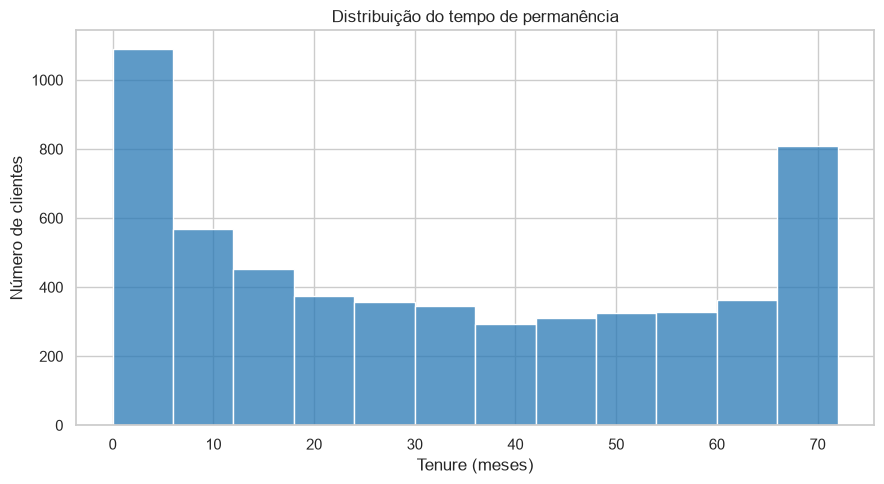

Interpretação: n=5,615; média=32.31 meses e mediana=29. A mediana divide os clientes válidos em duas metades; a média acima dela é compatível com maior peso de permanências longas. Moda=1 mês(es).


In [15]:
tenure = dados['tenure'].dropna().astype(float)
resumo_tenure = pd.DataFrame([{
    'n': tenure.count(), 'media_meses': tenure.mean(), 'mediana_meses': tenure.median(),
    'desvio_padrao_meses': tenure.std(), 'q1_meses': tenure.quantile(.25),
    'q3_meses': tenure.quantile(.75), 'moda_meses': tenure.mode().iloc[0],
}])
display(resumo_tenure.round(2))
resumo_tenure.to_csv(DIR_TABELAS / 'q1_resumo_tenure.csv', index=False)

fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(tenure, binwidth=6, binrange=(0, 72), color='#2878B5', ax=ax)
ax.set(title='Distribuição do tempo de permanência', xlabel='Tenure (meses)', ylabel='Número de clientes')
fig.tight_layout()
fig.savefig(DIR_GRAFICOS / 'q1_histograma_tenure.png', dpi=160, bbox_inches='tight')
plt.show()
print(f'Interpretação: n={len(tenure):,}; média={tenure.mean():.2f} meses e mediana={tenure.median():.0f}. A mediana divide os clientes válidos em duas metades; a média acima dela é compatível com maior peso de permanências longas. Moda={tenure.mode().iloc[0]:.0f} mês(es).')

## 2. Quais valores de cobrança mensal são mais comuns?

**Objetivo:** avaliar centro, dispersão e concentrações de `MonthlyCharges`. A moda é o valor exato mais frequente; o histograma evidencia também faixas concentradas.

,n,media,mediana,desvio_padrao,q1,q3,minimo,maximo,moda_valor,moda_frequencia
0,5634,64.61,70.3,30.15,35.16,89.8,18.4,118.65,20.05,52


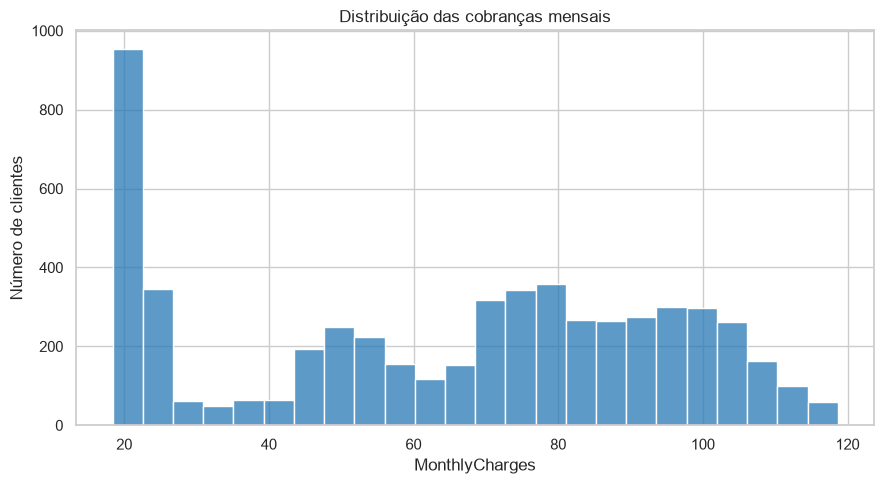

Interpretação: média=64.61, mediana=70.30, desvio-padrão=30.15; valor exato modal=20.05 (n=52). A faixa de maior frequência no histograma é (18.3, 22.577] (n=953); média e mediana não coincidem, indicando concentração não simétrica.


In [16]:
cobranca = dados['MonthlyCharges'].dropna()
resumo_cobranca = pd.DataFrame([{
    'n': cobranca.count(), 'media': cobranca.mean(), 'mediana': cobranca.median(),
    'desvio_padrao': cobranca.std(), 'q1': cobranca.quantile(.25),
    'q3': cobranca.quantile(.75), 'minimo': cobranca.min(), 'maximo': cobranca.max(),
    'moda_valor': cobranca.mode().iloc[0], 'moda_frequencia': int(cobranca.value_counts().max()),
}])
display(resumo_cobranca.round(2))
resumo_cobranca.to_csv(DIR_TABELAS / 'q2_resumo_monthly_charges.csv', index=False)

fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(cobranca, bins=24, color='#2878B5', ax=ax)
ax.set(title='Distribuição das cobranças mensais', xlabel='MonthlyCharges', ylabel='Número de clientes')
fig.tight_layout()
fig.savefig(DIR_GRAFICOS / 'q2_histograma_monthly_charges.png', dpi=160, bbox_inches='tight')
plt.show()
faixa_modal = pd.cut(cobranca, bins=24).value_counts().idxmax()
print(f"Interpretação: média={cobranca.mean():.2f}, mediana={cobranca.median():.2f}, desvio-padrão={cobranca.std():.2f}; valor exato modal={cobranca.mode().iloc[0]:.2f} (n={cobranca.value_counts().max()}). A faixa de maior frequência no histograma é {faixa_modal} (n={pd.cut(cobranca, bins=24).value_counts().max()}); média e mediana não coincidem, indicando concentração não simétrica.")

### Como são calculadas as correlações

Pearson mede associação linear; Spearman mede associação monotônica sobre postos médios. Para não introduzir dependência de `scipy`, Spearman é calculado como correlação de Pearson entre os postos das observações. Em ambos os casos, a análise usa pares completos e correlação não implica causalidade.

In [17]:
def correlacoes(par: pd.DataFrame, x: str, y: str) -> dict:
    pares = par[[x, y]].dropna().astype(float)
    return {
        'n': len(pares),
        'pearson': pares[x].corr(pares[y], method='pearson'),
        'spearman': pares[x].rank(method='average').corr(pares[y].rank(method='average'), method='pearson'),
    }

def comparacao_imputacao(x: str) -> pd.DataFrame:
    observado = dados.loc[~dados['TotalCharges_imputado'], [x, 'TotalCharges']]
    completo = dados[[x, 'TotalCharges']]
    resultados = []
    for escopo, par in [('Principal: sem imputados', observado), ('Complementar: com imputados', completo)]:
        resultados.append({'escopo': escopo, 'variavel_x': x, **correlacoes(par, x, 'TotalCharges')})
    return pd.DataFrame(resultados)


## 3. Clientes que permanecem mais tempo acumulam mais cobranças?

**Objetivo:** relacionar `tenure` e `TotalCharges`. A análise principal exclui todas as linhas sinalizadas como imputadas; a complementar inclui imputados e usa pares completos. A reta é uma tendência linear descritiva, não causal.

,escopo,variavel_x,n,pearson,spearman
0,Principal: sem imputados,tenure,5338,0.8229,0.8869
1,Complementar: com imputados,tenure,5615,0.8255,0.8890


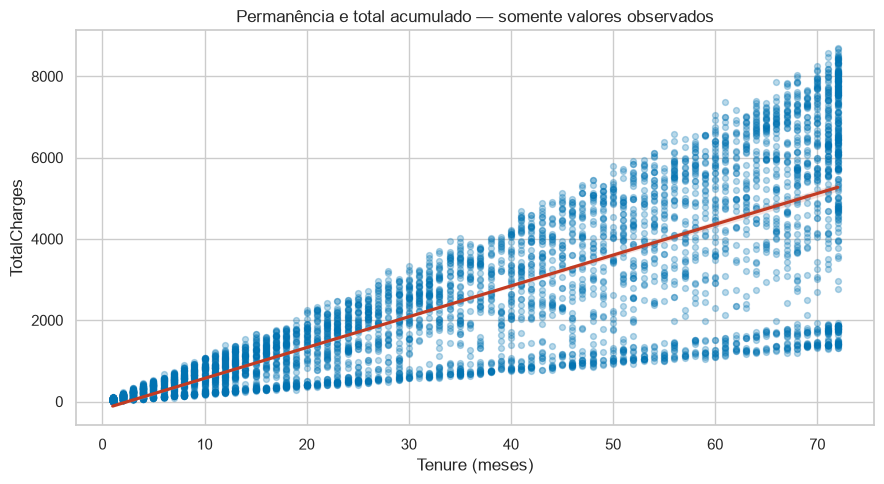

Principal: 5,338 pares; Pearson=0.823, Spearman=0.887. Complementar: 5,615 pares; Pearson=0.825, Spearman=0.889.
Interpretação: associação positiva forte entre permanência e total acumulado. Incluir os imputados altera Pearson em +0.0026 e Spearman em +0.0021; portanto, neste conjunto o efeito numérico é pequeno, mas os valores estimados não são observações e a conclusão principal se mantém restrita aos observados.


In [18]:
q3 = comparacao_imputacao('tenure')
display(q3.round(4))
q3.to_csv(DIR_TABELAS / 'q3_tenure_total_charges.csv', index=False)
pares_q3 = dados.loc[~dados['TotalCharges_imputado'], ['tenure', 'TotalCharges']].dropna().astype(float)
fig, ax = plt.subplots(figsize=(9, 5))
sns.regplot(data=pares_q3, x='tenure', y='TotalCharges', scatter_kws={'alpha': .28, 's': 18}, line_kws={'color': '#C23B22'}, ax=ax)
ax.set(title='Permanência e total acumulado — somente valores observados', xlabel='Tenure (meses)', ylabel='TotalCharges')
fig.tight_layout()
fig.savefig(DIR_GRAFICOS / 'q3_tenure_total_charges.png', dpi=160, bbox_inches='tight')
plt.show()
principal, complementar = q3.iloc[0], q3.iloc[1]
print(f"Principal: {int(principal['n']):,} pares; Pearson={principal['pearson']:.3f}, Spearman={principal['spearman']:.3f}. Complementar: {int(complementar['n']):,} pares; Pearson={complementar['pearson']:.3f}, Spearman={complementar['spearman']:.3f}.")
print(f"Interpretação: associação positiva forte entre permanência e total acumulado. Incluir os imputados altera Pearson em {complementar['pearson'] - principal['pearson']:+.4f} e Spearman em {complementar['spearman'] - principal['spearman']:+.4f}; portanto, neste conjunto o efeito numérico é pequeno, mas os valores estimados não são observações e a conclusão principal se mantém restrita aos observados.")

## 4. A cobrança mensal está relacionada ao total acumulado?

**Objetivo:** analisar `MonthlyCharges` × `TotalCharges` com o mesmo desenho de sensibilidade: principal sem imputações e complementar incluindo imputados.

,escopo,variavel_x,n,pearson,spearman
0,Principal: sem imputados,MonthlyCharges,5356,0.6515,0.6376
1,Complementar: com imputados,MonthlyCharges,5633,0.6523,0.6402


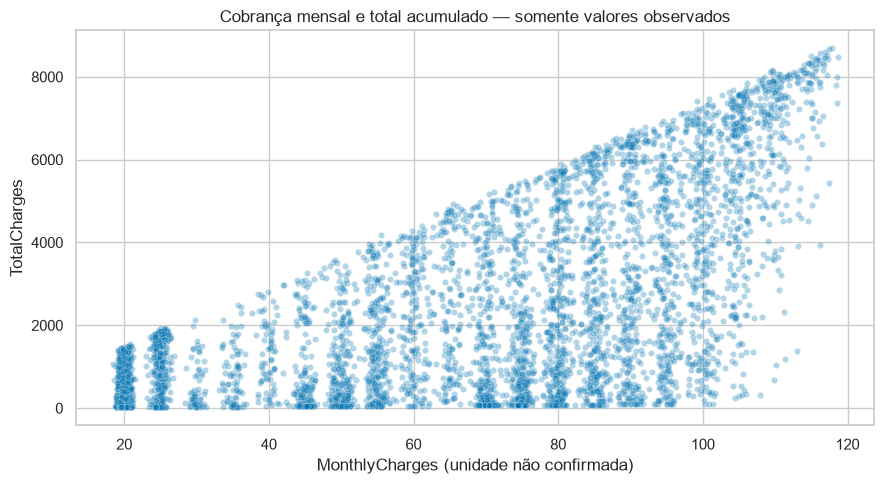

Principal: 5,356 pares; Pearson=0.651, Spearman=0.638. Complementar: 5,633 pares; Pearson=0.652, Spearman=0.640.
Interpretação: associação positiva; a força é moderada e próxima entre a correlação linear e monotônica. Incluir imputados altera Pearson em +0.0008 e Spearman em +0.0027. A relação também pode refletir duração de contrato e composição dos serviços; não demonstra causalidade.


In [19]:
q4 = comparacao_imputacao('MonthlyCharges')
display(q4.round(4))
q4.to_csv(DIR_TABELAS / 'q4_monthly_total_charges.csv', index=False)
pares_q4 = dados.loc[~dados['TotalCharges_imputado'], ['MonthlyCharges', 'TotalCharges']].dropna()
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=pares_q4, x='MonthlyCharges', y='TotalCharges', alpha=.3, s=20, ax=ax)
ax.set(title='Cobrança mensal e total acumulado — somente valores observados', xlabel='MonthlyCharges (unidade não confirmada)', ylabel='TotalCharges')
fig.tight_layout()
fig.savefig(DIR_GRAFICOS / 'q4_monthly_total_charges.png', dpi=160, bbox_inches='tight')
plt.show()
principal, complementar = q4.iloc[0], q4.iloc[1]
print(f"Principal: {int(principal['n']):,} pares; Pearson={principal['pearson']:.3f}, Spearman={principal['spearman']:.3f}. Complementar: {int(complementar['n']):,} pares; Pearson={complementar['pearson']:.3f}, Spearman={complementar['spearman']:.3f}.")
print(f"Interpretação: associação positiva; a força é moderada e próxima entre a correlação linear e monotônica. Incluir imputados altera Pearson em {complementar['pearson'] - principal['pearson']:+.4f} e Spearman em {complementar['spearman'] - principal['spearman']:+.4f}. A relação também pode refletir duração de contrato e composição dos serviços; não demonstra causalidade.")

## 5. A renda mensal está relacionada à cobrança mensal?

**Objetivo:** explorar a associação entre `MonthlyIncome` e `MonthlyCharges`. **Limitação importante:** a unidade, a pessoa a que a renda se refere e o método de obtenção da variável não foram confirmados; os resultados são estritamente exploratórios.

,n,pearson,spearman
0,5634,0.0111,0.0125


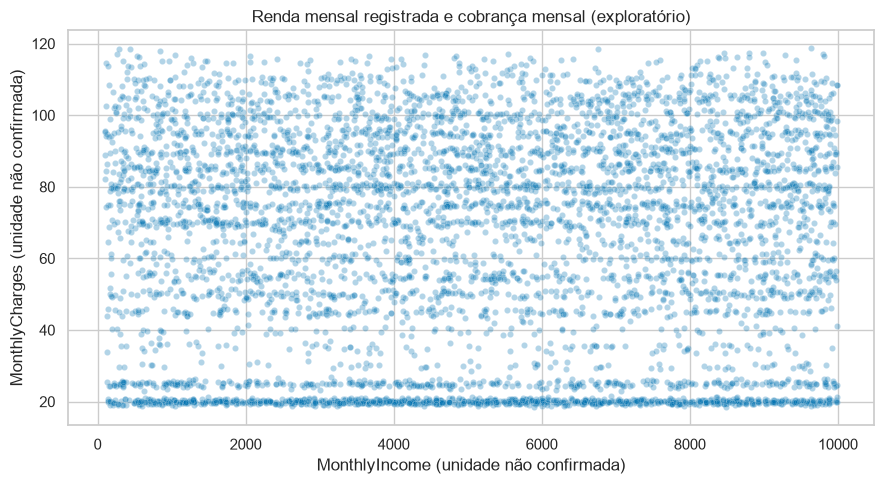

Interpretação: n=5,634; Pearson=0.011 e Spearman=0.012, ambos próximos de zero nesta amostra. Não há evidência de associação monotônica relevante nos dados; dada a semântica não confirmada de MonthlyIncome, não se deve concluir sobre renda ou capacidade de pagamento.


In [20]:
pares_q5 = dados[['MonthlyIncome', 'MonthlyCharges']].dropna()
q5_metricas = correlacoes(pares_q5, 'MonthlyIncome', 'MonthlyCharges')
q5 = pd.DataFrame([q5_metricas])
display(q5.round(4))
q5.to_csv(DIR_TABELAS / 'q5_monthly_income_monthly_charges.csv', index=False)
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=pares_q5, x='MonthlyIncome', y='MonthlyCharges', alpha=.3, s=20, ax=ax)
ax.set(title='Renda mensal registrada e cobrança mensal (exploratório)', xlabel='MonthlyIncome (unidade não confirmada)', ylabel='MonthlyCharges (unidade não confirmada)')
fig.tight_layout()
fig.savefig(DIR_GRAFICOS / 'q5_monthly_income_monthly_charges.png', dpi=160, bbox_inches='tight')
plt.show()
print(f"Interpretação: n={q5_metricas['n']:,}; Pearson={q5_metricas['pearson']:.3f} e Spearman={q5_metricas['spearman']:.3f}, ambos próximos de zero nesta amostra. Não há evidência de associação monotônica relevante nos dados; dada a semântica não confirmada de MonthlyIncome, não se deve concluir sobre renda ou capacidade de pagamento.")

## 6. O tipo de contrato está associado ao cancelamento?

**Objetivo:** calcular `Churn` como percentual **dentro de cada tipo de `Contract`**. O denominador de cada barra é o total de clientes daquele contrato, não o total da base.

Churn,No_n,Yes_n,No_pct,Yes_pct,total_contrato,taxa_churn_pct
Contract,,,,,,
Month-to-month,1777,1322,57.34,42.66,3099,42.66
One year,1050,138,88.38,11.62,1188,11.62
Two year,1303,44,96.73,3.27,1347,3.27


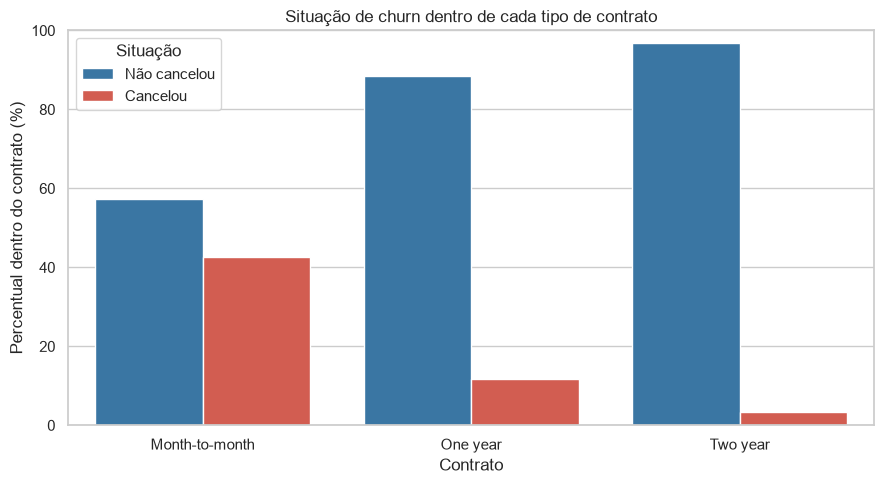

Interpretação: taxas de cancelamento por contrato: Month-to-month: 42.66%; One year: 11.62%; Two year: 3.27%. A diferença descritiva entre grupos não prova que o contrato cause ou previna cancelamento; podem existir diferenças de perfil e seleção.


In [21]:
contagens_contrato = pd.crosstab(dados['Contract'], dados['Churn']).reindex(columns=['No', 'Yes'], fill_value=0)
percentuais_contrato = contagens_contrato.div(contagens_contrato.sum(axis=1), axis=0).mul(100)
q6 = contagens_contrato.add_suffix('_n').join(percentuais_contrato.add_suffix('_pct'))
q6['total_contrato'] = contagens_contrato.sum(axis=1)
q6['taxa_churn_pct'] = percentuais_contrato['Yes']
display(q6.round(2))
q6.to_csv(DIR_TABELAS / 'q6_churn_por_contrato.csv')

grafico_q6 = percentuais_contrato.rename(columns={'No': 'Não cancelou', 'Yes': 'Cancelou'}).reset_index().melt(id_vars='Contract', var_name='Churn', value_name='Percentual')
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(
    data=grafico_q6,
    x='Contract',
    y='Percentual',
    hue='Churn',
    palette={
        'Não cancelou': '#2878B5',
        'Cancelou': '#E74C3C'
    },
    ax=ax
)
ax.set(title='Situação de churn dentro de cada tipo de contrato', xlabel='Contrato', ylabel='Percentual dentro do contrato (%)', ylim=(0, 100))
ax.legend(title='Situação')
fig.tight_layout()
fig.savefig(DIR_GRAFICOS / 'q6_churn_por_contrato.png', dpi=160, bbox_inches='tight')
plt.show()
taxas = percentuais_contrato['Yes'].sort_values(ascending=False)
print('Interpretação: taxas de cancelamento por contrato: ' + '; '.join(f'{contrato}: {taxa:.2f}%' for contrato, taxa in taxas.items()) + '. A diferença descritiva entre grupos não prova que o contrato cause ou previna cancelamento; podem existir diferenças de perfil e seleção.')

## 7. Clientes que cancelaram tinham menor permanência?

**Objetivo:** comparar a distribuição e as medianas de `tenure` por `Churn`. São excluídos somente os registros sem tenure conhecido; o tamanho de cada grupo é informado.

,n,mediana,media,q1,q3
Churn,,,,,
No,4119,37.0,37.38,14.0,61.0
Yes,1496,10.0,18.33,2.0,30.0


Tenure conhecido: 5,615 de 5,634 registros; excluídos por tenure ausente: 19.


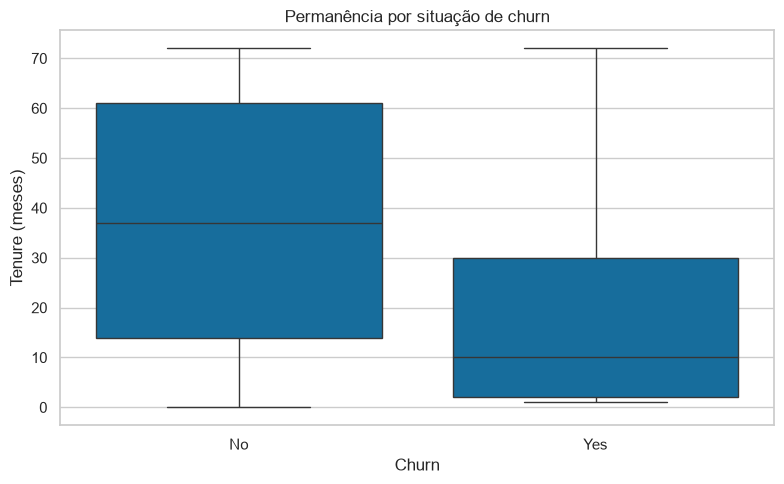

Interpretação: medianas de 37 meses (não cancelou) e 10 meses (cancelou), diferença de 27 meses. A distribuição entre quem cancelou está deslocada para menores permanências; a comparação é descritiva e não estabelece causa.


In [22]:
tenure_churn = dados.dropna(subset=['tenure']).copy()
resumo_q7 = tenure_churn.groupby('Churn', observed=True)['tenure'].agg(
    n='count', mediana='median', media='mean', q1=lambda s: s.quantile(.25), q3=lambda s: s.quantile(.75)
).reindex(['No', 'Yes'])
display(resumo_q7.round(2))
resumo_q7.to_csv(DIR_TABELAS / 'q7_tenure_por_churn.csv')
print(f"Tenure conhecido: {len(tenure_churn):,} de {len(dados):,} registros; excluídos por tenure ausente: {dados['tenure'].isna().sum():,}.")

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=tenure_churn, x='Churn', y='tenure', order=['No', 'Yes'], showfliers=False, ax=ax)
ax.set(title='Permanência por situação de churn', xlabel='Churn', ylabel='Tenure (meses)')
fig.tight_layout()
fig.savefig(DIR_GRAFICOS / 'q7_tenure_por_churn.png', dpi=160, bbox_inches='tight')
plt.show()
mediana_nao = resumo_q7.loc['No', 'mediana']
mediana_sim = resumo_q7.loc['Yes', 'mediana']
print(f'Interpretação: medianas de {mediana_nao:.0f} meses (não cancelou) e {mediana_sim:.0f} meses (cancelou), diferença de {mediana_nao - mediana_sim:.0f} meses. A distribuição entre quem cancelou está deslocada para menores permanências; a comparação é descritiva e não estabelece causa.')

## 8. Quais variáveis numéricas apresentam maior relação entre si?

**Objetivo:** visualizar Pearson e Spearman para as variáveis quantitativas adequadas: `tenure`, `MonthlyCharges`, `TotalCharges` e `MonthlyIncome`. `customerID` é identificador, `TotalCharges_imputado` é controle booleano e variáveis categóricas não são convertidas em números. Para evitar incorporar valores estimados no total, esta comparação filtra `TotalCharges_imputado == False`; correlações usam pares completos.

,variavel,tenure,MonthlyCharges,TotalCharges,MonthlyIncome
0,tenure,1.000,0.243,0.823,-0.004
1,MonthlyCharges,0.243,1.000,0.651,0.012
2,TotalCharges,0.823,0.651,1.000,0.006
3,MonthlyIncome,-0.004,0.012,0.006,1.000


,variavel,tenure,MonthlyCharges,TotalCharges,MonthlyIncome
0,tenure,1.000,0.271,0.887,-0.001
1,MonthlyCharges,0.271,1.000,0.638,0.013
2,TotalCharges,0.887,0.638,1.000,0.008
3,MonthlyIncome,-0.001,0.013,0.008,1.000


,variavel,tenure,MonthlyCharges,TotalCharges,MonthlyIncome
0,tenure,5338,5338,5338,5338
1,MonthlyCharges,5338,5357,5356,5357
2,TotalCharges,5338,5356,5356,5356
3,MonthlyIncome,5338,5357,5356,5357


Linhas elegíveis após excluir imputados: 5,357; a tabela N indica o número de pares completos usado em cada correlação.


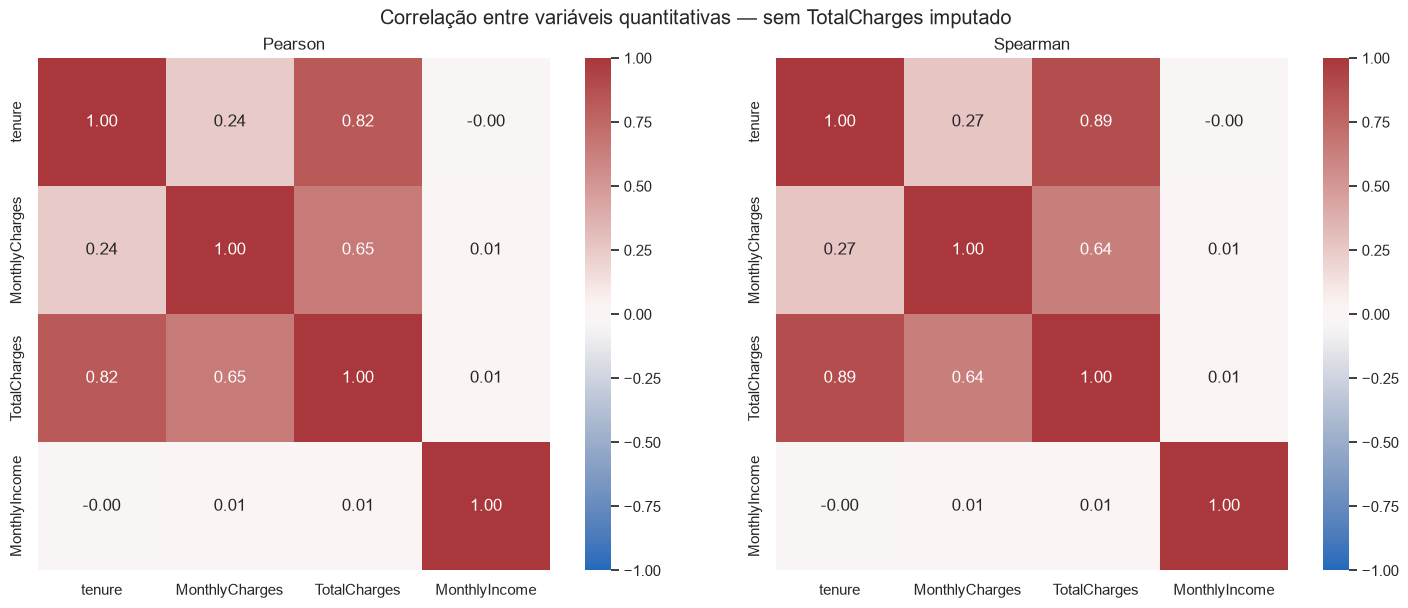

Interpretação: maior associação linear absoluta entre tenure e TotalCharges (Pearson=0.823); seu Spearman é 0.887. A relação tenure–TotalCharges é a mais forte; MonthlyIncome tem associações praticamente nulas, mas sua definição continua incerta. Matriz é descritiva, com exclusão de imputados e pares completos.


In [23]:
colunas_numericas = ['tenure', 'MonthlyCharges', 'TotalCharges', 'MonthlyIncome']
numericas_observadas = dados.loc[~dados['TotalCharges_imputado'], colunas_numericas].astype(float)
pearson_q8 = numericas_observadas.corr(method='pearson')
spearman_q8 = numericas_observadas.rank(method='average').corr(method='pearson')
n_q8 = numericas_observadas.notna().astype('int64').T.dot(numericas_observadas.notna().astype('int64'))
pearson_q8.to_csv(DIR_TABELAS / 'q8_correlacao_pearson.csv')
spearman_q8.to_csv(DIR_TABELAS / 'q8_correlacao_spearman.csv')
n_q8.to_csv(DIR_TABELAS / 'q8_n_pares.csv')
display(pearson_q8.round(3).rename_axis('variavel').reset_index())
display(spearman_q8.round(3).rename_axis('variavel').reset_index())
display(n_q8.rename_axis('variavel').reset_index())
print(f'Linhas elegíveis após excluir imputados: {len(numericas_observadas):,}; a tabela N indica o número de pares completos usado em cada correlação.')

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(pearson_q8, annot=True, fmt='.2f', cmap='vlag', center=0, vmin=-1, vmax=1, square=True, ax=axes[0])
axes[0].set_title('Pearson')
sns.heatmap(spearman_q8, annot=True, fmt='.2f', cmap='vlag', center=0, vmin=-1, vmax=1, square=True, ax=axes[1])
axes[1].set_title('Spearman')
fig.suptitle('Correlação entre variáveis quantitativas — sem TotalCharges imputado')
fig.tight_layout()
fig.savefig(DIR_GRAFICOS / 'q8_heatmap_correlacoes.png', dpi=160, bbox_inches='tight')
plt.show()

pares_forca = pearson_q8.where(~pd.DataFrame([[i == j for j in pearson_q8.columns] for i in pearson_q8.index], index=pearson_q8.index, columns=pearson_q8.columns)).stack().abs().sort_values(ascending=False)
forca = pares_forca.index[0]
print(f'Interpretação: maior associação linear absoluta entre {forca[0]} e {forca[1]} (Pearson={pearson_q8.loc[forca[0], forca[1]]:.3f}); seu Spearman é {spearman_q8.loc[forca[0], forca[1]]:.3f}. A relação tenure–TotalCharges é a mais forte; MonthlyIncome tem associações praticamente nulas, mas sua definição continua incerta. Matriz é descritiva, com exclusão de imputados e pares completos.')

## Conclusão geral e limitações

As células finais consolidam achados calculados diretamente da Silver. Interprete associações como descritivas, não causais. Limitações: 19 ausências em `tenure`; 1 ausência remanescente em `TotalCharges`; 277 valores estimados, cuja inclusão é mostrada separadamente nas perguntas 3 e 4; unidade e significado de `MonthlyIncome` não confirmados; e possíveis variáveis de confusão, seleção e composição de serviços não controladas. `TotalCharges` não é interpretado como independente de tenure e MonthlyCharges.

In [24]:
taxa_churn_contrato = percentuais_contrato['Yes']
maior_taxa_contrato = taxa_churn_contrato.idxmax()
menor_taxa_contrato = taxa_churn_contrato.idxmin()
resumo_final = pd.DataFrame([
    {'pergunta': 'Q1 tenure', 'resultado': f"n={len(tenure):,}; média {tenure.mean():.2f}; mediana {tenure.median():.0f} meses"},
    {'pergunta': 'Q2 MonthlyCharges', 'resultado': f"n={len(cobranca):,}; média {cobranca.mean():.2f}; mediana {cobranca.median():.2f}; moda {cobranca.mode().iloc[0]:.2f}"},
    {'pergunta': 'Q3 tenure × TotalCharges', 'resultado': f"Pearson/Spearman observado {q3.iloc[0]['pearson']:.3f}/{q3.iloc[0]['spearman']:.3f}; com imputados {q3.iloc[1]['pearson']:.3f}/{q3.iloc[1]['spearman']:.3f}"},
    {'pergunta': 'Q4 MonthlyCharges × TotalCharges', 'resultado': f"Pearson/Spearman observado {q4.iloc[0]['pearson']:.3f}/{q4.iloc[0]['spearman']:.3f}; com imputados {q4.iloc[1]['pearson']:.3f}/{q4.iloc[1]['spearman']:.3f}"},
    {'pergunta': 'Q5 MonthlyIncome × MonthlyCharges', 'resultado': f"Pearson/Spearman {q5_metricas['pearson']:.3f}/{q5_metricas['spearman']:.3f}; semântica da renda não confirmada"},
    {'pergunta': 'Q6 contrato × churn', 'resultado': f"maior taxa: {taxa_churn_contrato.loc[maior_taxa_contrato]:.2f}% ({maior_taxa_contrato}); menor taxa: {taxa_churn_contrato.loc[menor_taxa_contrato]:.2f}% ({menor_taxa_contrato})"},
    {'pergunta': 'Q7 tenure por churn', 'resultado': f"medianas não churn={mediana_nao:.0f}, churn={mediana_sim:.0f} meses; n={len(tenure_churn):,}"},
    {'pergunta': 'Q8 correlações numéricas', 'resultado': f"maior Pearson absoluto: {forca[0]} × {forca[1]} = {pearson_q8.loc[forca[0], forca[1]]:.3f}; imputados excluídos"},
])
display(resumo_final)
resumo_final.to_csv(DIR_TABELAS / 'gold_resumo_geral.csv', index=False)
print(f'Conclusão: permanências maiores estão associadas a totais acumulados maiores; a cobrança mensal tem associação positiva moderada com o total; churn observado é mais frequente em contratos mensais e os clientes que cancelaram apresentam menor mediana de tenure. Estes padrões descrevem esta base, não efeitos causais. Ver limitações acima.')
print(f'Arquivos Gold salvos em: {DIR_TABELAS} e {DIR_GRAFICOS}')

,pergunta,resultado
0,Q1 tenure,"n=5,615; média 32.31; mediana 29 meses"
1,Q2 MonthlyCharges,"n=5,634; média 64.61; mediana 70.30; moda 20.05"
2,Q3 tenure × TotalCharges,Pearson/Spearman observado 0.823/0.887; com im...
3,Q4 MonthlyCharges × TotalCharges,Pearson/Spearman observado 0.651/0.638; com im...
4,Q5 MonthlyIncome × MonthlyCharges,Pearson/Spearman 0.011/0.012; semântica da ren...
5,Q6 contrato × churn,maior taxa: 42.66% (Month-to-month); menor tax...
6,Q7 tenure por churn,"medianas não churn=37, churn=10 meses; n=5,615"
7,Q8 correlações numéricas,maior Pearson absoluto: tenure × TotalCharges ...


Conclusão: permanências maiores estão associadas a totais acumulados maiores; a cobrança mensal tem associação positiva moderada com o total; churn observado é mais frequente em contratos mensais e os clientes que cancelaram apresentam menor mediana de tenure. Estes padrões descrevem esta base, não efeitos causais. Ver limitações acima.
Arquivos Gold salvos em: c:\Users\52384154869\Documents\projeto-integrador-databricks\bases\gold\tabelas e c:\Users\52384154869\Documents\projeto-integrador-databricks\bases\gold\graficos
